In [75]:
import csv
import json
import numpy as np

def convert_csv_to_json(csv_file_path, json_file_path):
    # Dictionary to store data grouped by time
    data_by_time = {}
    
    # Read CSV file
    with open(csv_file_path, 'r') as csv_file:
        csv_reader = csv.DictReader(csv_file)
        
  
        # Process each row
        for row in csv_reader:
            time = str(int(float(row['time']))+1)  # Convert time to string key

            if int(float(row['time']))+1 == 1:
                
                # Create time entry if it doesn't exist
                if time not in data_by_time:
                    data_by_time[time] = []

                rot=0.025+1+0.002
                rotationAxisX = 0
                rotationAxisY = 168
                rotationAngle = rot * np.pi # A slight rotation to align with the video
                x = float(row['y'])*0.0714-49.57 
                y = float(row['x'])*0.0714+125.5
                originalAngle = ((float(row['angle']))/np.pi)*(-1)


                L = np.sqrt((x-rotationAxisX)**2 + (y-rotationAxisY)**2) # Distance from rotation axis
                rotX = L * np.cos(rotationAngle + np.arctan2(y-rotationAxisY, x-rotationAxisX)) + rotationAxisX
                rotY = L * np.sin(rotationAngle + np.arctan2(y-rotationAxisY, x-rotationAxisX)) + rotationAxisY

                newAngle = originalAngle + rot   
                
                # Create object with required properties
                obj = {
                    "x": np.round(rotX, 2),
                    "y": np.round(rotY - 5.5, 2),
                    "an": np.round(newAngle, 2),
                    "le": np.round(float(row['length'])*0.06, 2),
                    "id": str(row['ID']),
                    "parent": int(float(row['parent']))
                }


                if obj["y"] > 141 and obj["y"] < 199 and obj["x"] > -49.5 and obj["x"] < 49.5:
               
                    data_by_time[time].append(obj)

            
            

        

        #add lineage 
        lineage = {}  # Dictionary where key is bacterium ID and value is parent ID
        for time, bacteria in data_by_time.items():
            if time == "time":
                continue
              
            for bacterium in bacteria:
                lineage[bacterium["id"]] = bacterium["parent"]  
            
            


        data_by_time["lineage"] = lineage

    #replace all timesteps with the first timestep's data and make it longer till 1000
    first_timestep_data = data_by_time.get("1", [])  # Get data for the first timestep
    for i in range(1, 300):
        data_by_time[str(i)] = first_timestep_data

    
    # Write to JSON file
    with open(json_file_path, 'w') as json_file:
        json.dump(data_by_time, json_file, separators=(',', ':'), ensure_ascii=False)

if __name__ == "__main__":
    position = "pos7"
    input_csv = "./results/"+f"{position}_trajectories.csv"
    output_json = "./modern/output" + f"{position}.json"
    convert_csv_to_json(input_csv, output_json)


In [64]:
import json

def analyze_coordinates(json_file_path):
    with open(json_file_path, "r") as file:
        data = json.load(file)

    x_values, y_values, angle_values = [], [], []

    for time_key, objects in data.items():
        if time_key == "time" or objects is None:
            continue

        # Normalize to iterable of object dicts
        if isinstance(objects, list):
            iterable = objects
        elif isinstance(objects, dict):
            # If dict of objects: {"0": {...}, "1": {...}}
            iterable = objects.values()
        else:
            continue

        for obj in iterable:
            if not isinstance(obj, dict):
                continue
            if {"x", "y", "an"} <= obj.keys():
                x_values.append(obj["x"])
                y_values.append(obj["y"])
                angle_values.append(obj["an"])

    if not x_values:
        print(f"No valid coordinates found in: {json_file_path}")
        return

    x_min, x_max = min(x_values), max(x_values)
    y_min, y_max = min(y_values), max(y_values)
    angle_min, angle_max = min(angle_values), max(angle_values)

    print("\nCoordinate Ranges Analysis:")
    print("-" * 30)
    print(f"X-coordinate range:\n  Minimum: {x_min:.2f}\n  Maximum: {x_max:.2f}\n  Range: {x_max - x_min:.2f}")
    print(f"\nY-coordinate range:\n  Minimum: {y_min:.2f}\n  Maximum: {y_max:.2f}\n  Range: {y_max - y_min:.2f}")
    print(f"\nAngle range:\n  Minimum: {angle_min:.2f}\n  Maximum: {angle_max:.2f}\n  Range: {angle_max - angle_min:.2f}")
    

if __name__ == "__main__":
    input_json = "modern/outputpos7.json"
    analyze_coordinates(input_json)


if __name__ == "__main__":
    input_json = "./CompressedStates/HighRes.json"
    analyze_coordinates(input_json)



Coordinate Ranges Analysis:
------------------------------
X-coordinate range:
  Minimum: -50.76
  Maximum: 51.06
  Range: 101.82

Y-coordinate range:
  Minimum: 126.99
  Maximum: 199.00
  Range: 72.01

Angle range:
  Minimum: 0.53
  Maximum: 1.52
  Range: 0.99

Coordinate Ranges Analysis:
------------------------------
X-coordinate range:
  Minimum: -49.55
  Maximum: 49.56
  Range: 99.11

Y-coordinate range:
  Minimum: 137.73
  Maximum: 199.56
  Range: 61.83

Angle range:
  Minimum: 0.00
  Maximum: 1.00
  Range: 1.00


In [65]:
import json

with open("./CompressedStates/HighRes.json", "r") as file:
    data1 = json.load(file)

print("data1 is a " , type(data1))

with open("./modern/outputpos7.json", "r") as file:
    data2 = json.load(file)

print("data2 is a " , type(data2))


print("first 5 top-level keys of data1:", list(data1.keys())[:5])  # Print first 5 keys to check structure
print("last 5 top-level keys of data1:", list(data1.keys())[-5:])  # Print last 5 keys to check structure

print("first 5 top-level keys of data2:", list(data2.keys())[:5])  # Print first 5 keys to check structure
print("last 5 top-level keys of data2:", list(data2.keys())[-5:])  # Print last 5 keys to check structure

data1 is a  <class 'dict'>
data2 is a  <class 'dict'>
first 5 top-level keys of data1: ['1', '2', '3', '4', '5']
last 5 top-level keys of data1: ['4117', '4118', '4119', '4120', 'lineage']
first 5 top-level keys of data2: ['1', 'lineage', '2', '3', '4']
last 5 top-level keys of data2: ['996', '997', '998', '999', '1000']


In [47]:
print(data2["lineage"])

{'1': 0, '2': 0, '3': 0, '4': 0, '5': 0, '6': 0, '7': 0, '8': 0, '9': 0, '10': 0, '11': 0, '12': 0, '13': 0, '14': 0, '15': 0, '16': 0, '17': 0, '18': 0, '19': 0, '20': 0, '21': 0, '22': 0, '23': 0, '24': 0, '25': 0, '26': 0, '27': 0, '28': 0, '29': 0, '30': 0, '31': 0, '32': 0, '33': 0, '34': 0, '35': 0, '36': 0, '37': 0, '38': 0, '39': 0, '40': 0, '41': 0, '42': 0, '43': 0, '44': 0, '45': 0, '46': 0, '47': 0, '48': 0, '49': 0, '50': 0, '51': 0, '52': 0, '53': 0, '54': 0, '55': 0, '56': 0, '57': 0, '58': 0, '59': 0, '60': 0, '61': 0, '62': 0, '63': 0, '64': 0, '65': 0, '66': 0, '67': 0, '68': 0, '69': 0, '70': 0, '71': 0, '72': 0, '73': 0, '74': 0, '75': 0, '76': 0, '77': 0, '78': 0, '79': 0, '80': 0, '81': 0, '82': 0, '83': 0, '84': 0, '85': 0, '86': 0, '87': 0, '88': 0, '89': 0, '90': 0, '91': 0, '92': 0, '93': 0, '94': 0, '95': 0, '96': 0, '97': 0, '98': 0, '99': 0, '100': 0, '101': 0, '102': 0, '103': 0, '104': 0, '105': 0, '106': 0, '107': 0, '108': 0, '109': 0, '110': 0, '111': 

data is a  <class 'dict'>


first 5 top-level keys: ['1', '2', '3', '4', '5']
last 5 top-level keys: ['118', '119', '120', '121', 'lineage']


In [22]:
import numpy as np

def overlap_summary(name, data, overlap_keys):
    counts = []
    x_vals, y_vals, an_vals, le_vals = [], [], [], []
    ids_seen = set()
    missing_fields = 0

    for t in overlap_keys:
        objs = data.get(t, [])
        if not isinstance(objs, list):
            continue

        counts.append(len(objs))
        ids_in_frame = set()

        for o in objs:
            if not isinstance(o, dict):
                continue

            required = {"x", "y", "an", "id"}
            if not required.issubset(o.keys()):
                missing_fields += 1
                continue

            x_vals.append(o["x"])
            y_vals.append(o["y"])
            an_vals.append(o["an"])
            if "le" in o:
                le_vals.append(o["le"])

            oid = str(o["id"])
            ids_seen.add(oid)
            ids_in_frame.add(oid)

        if len(ids_in_frame) != len(objs):
            pass

    lineage = data.get("lineage", {})
    lineage_ids = set(lineage.keys()) if isinstance(lineage, dict) else set()

    print(f"\n=== {name} (overlap window only) ===")
    print("overlap time points:", len(overlap_keys), "| first:", overlap_keys[0] if overlap_keys else None, "| last:", overlap_keys[-1] if overlap_keys else None)
    if counts:
        print("objects/time -> min:", int(np.min(counts)), "max:", int(np.max(counts)), "mean:", round(float(np.mean(counts)), 2))

    print("unique observed ids in overlap:", len(ids_seen))
    print("lineage entries:", len(lineage_ids))
    print("records missing required fields:", missing_fields)

    def rng(vals, label):
        if vals:
            print(f"{label} -> min: {min(vals):.2f}, max: {max(vals):.2f}, mean: {np.mean(vals):.2f}, std: {np.std(vals):.2f}")

    rng(x_vals, "x")
    rng(y_vals, "y")
    rng(an_vals, "an")
    rng(le_vals, "le")

    print("ids in lineage not observed in overlap:", len(lineage_ids - ids_seen))
    print("observed overlap ids not in lineage:", len(ids_seen - lineage_ids))


def numeric_time_keys(d):
    return sorted([k for k in d.keys() if str(k).isdigit()], key=lambda x: int(x))

keys1 = set(numeric_time_keys(data1))
keys2 = set(numeric_time_keys(data2))
overlap = sorted(keys1 & keys2, key=lambda x: int(x))

print("Shared time window:", overlap[0] if overlap else None, "to", overlap[-1] if overlap else None)
print("Shared time points:", len(overlap))

overlap_summary("data1", data1, overlap)
overlap_summary("data2", data2, overlap)

Shared time window: 1 to 121
Shared time points: 121

=== data1 (overlap window only) ===
overlap time points: 121 | first: 1 | last: 121
objects/time -> min: 928 max: 1353 mean: 1124.23
unique observed ids in overlap: 2833
lineage entries: 76376
records missing required fields: 0
x -> min: -49.51, max: 49.51, mean: 0.01, std: 28.44
y -> min: 137.94, max: 199.53, mean: 169.90, std: 17.10
an -> min: 0.00, max: 1.00, mean: 0.51, std: 0.31
le -> min: 1.14, max: 7.25, mean: 3.68, std: 1.14
ids in lineage not observed in overlap: 73543
observed overlap ids not in lineage: 0

=== data2 (overlap window only) ===
overlap time points: 121 | first: 1 | last: 121
objects/time -> min: 1573 max: 1981 mean: 1771.6
unique observed ids in overlap: 7224
lineage entries: 7224
records missing required fields: 0
x -> min: -51.24, max: 51.62, mean: -1.06, std: 28.25
y -> min: 126.99, max: 199.26, mean: 167.61, std: 18.30
an -> min: 0.53, max: 1.53, mean: 1.05, std: 0.18
le -> min: 0.96, max: 14.85, mean: 3

In [94]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D



Kin = 10.0 #[μm^2/s]
Ksyn = 0.4 #[nM/s]
Kon = 0.001 #[1/(nM*s)]
Koff = 0.04 #[1/s]
DilRate = 0.00025672 #[1/s]
Pext = 0.20 #[nM]
A = 4.8 #[μm^2]


def ODE(y, Pext):
    Y = np.zeros_like(y)
    Y[0] = Kin * Pext/A + Koff * y[2] - Kon * y[0] * y[1] - DilRate * y[0] # rate of change of intracellular P
    Y[1] = Ksyn + Koff * y[2] - Kon * y[0] * y[1] - DilRate * y[1] # rate of change of intracellular R
    Y[2] = Kon * y[0] * y[1] - Koff * y[2] - DilRate * y[2] # rate of change of intracellular PR

    return Y



y=np.array([0,0,0]) # Initial conditions: [P, R, PR]  

def RK4_step(y, dt):
    k1 = ODE(y, Pext)
    k2 = ODE(y + 0.5 * dt * k1, Pext)
    k3 = ODE(y + 0.5 * dt * k2, Pext)
    k4 = ODE(y + dt * k3, Pext)

    return y + (dt / 6) * (k1 + 2*k2 + 2*k3 + k4)

[ti, tf, dt] = [0, 80000, 0.1]
number_of_steps = int((tf - ti) / dt)
time_points = np.linspace(ti, tf, number_of_steps)
results = np.zeros((number_of_steps, len(y)))
results[0] = y

for j in range(1, number_of_steps):
    results[j] = RK4_step(results[j-1], dt)
    #check for steady state (when the change in concentrations is very small)
    """  difference = np.linalg.norm(results[j] - results[j-1])
    if difference < 1e-3:
        print(f"Steady state reached at time {time_points[j]:.2f} for Pext={Pext:.2f}")
        break """

time_points = time_points * 1/60 * 1/60 # Convert time to hours for plotting





    

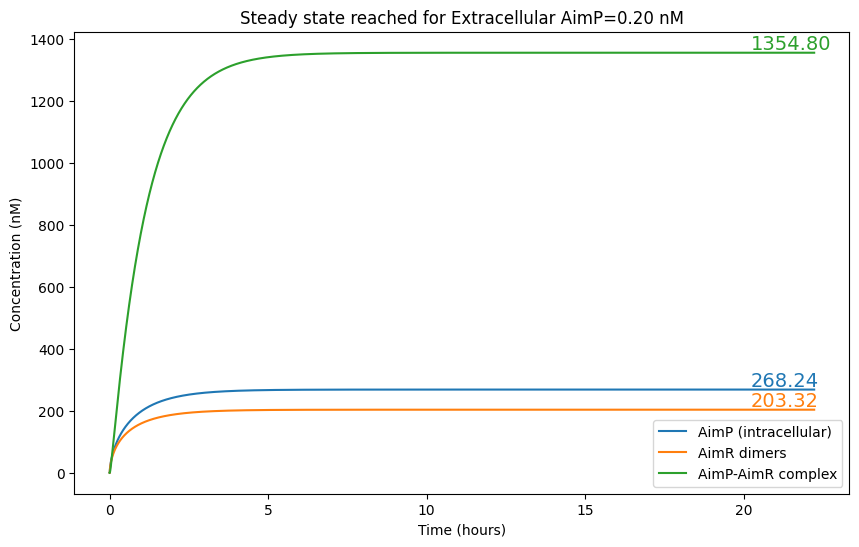

[ 268.24321274  203.32163808 1354.79615375]


In [96]:

plt.figure(figsize=(10, 6))
plt.plot(time_points, results[:, 0], label='AimP (intracellular)')
plt.plot(time_points, results[:, 1], label='AimR dimers')
plt.plot(time_points, results[:, 2], label='AimP-AimR complex')
plt.text(time_points[-1]-2, results[-1, 0]+10, f"{results[-1, 0]:.2f}", color='C0', fontsize=14)
plt.text(time_points[-1]-2, results[-1, 1]+10, f"{results[-1, 1]:.2f}", color='C1', fontsize=14)
plt.text(time_points[-1]-2, results[-1, 2]+10, f"{results[-1, 2]:.2f}", color='C2', fontsize=14)
plt.xlabel('Time (hours)')
plt.ylabel('Concentration (nM)')
plt.title(f"Steady state reached for Extracellular AimP={Pext:.2f} nM")
plt.legend()
plt.show()

print(results[-1])

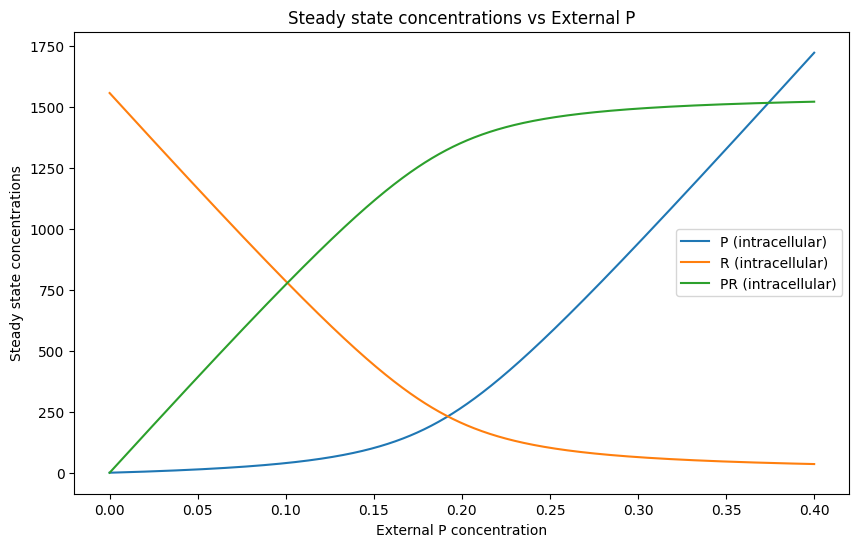

In [100]:
lam = Kon*Kin/(A*DilRate*(Koff+DilRate))
alphaR=Kon*Ksyn/(DilRate*(Koff+DilRate))

def x(Pext):
    x= ( -( alphaR -lam*Pext + 1) + np.sqrt(  (alphaR - lam*Pext + 1)**2 + 4*lam*Pext  )  ) / (2)
    return x

def y(Pext):
    y = (-(lam*Pext - alphaR + 1) + np.sqrt( (lam*Pext - alphaR + 1)**2 + 4*alphaR  )) / (2)
    return y

Panalytical = np.linspace(0, 0.4, 1000)



def generalSteadyState(Pext):
    p=Kin*Pext/(A*DilRate*(1+y(Pext)))
    r=Ksyn/(DilRate*(1+x(Pext)))
    pr=Kon*p*r/(Koff+DilRate)
    sol = np.array([p, r, pr])
    return sol

Analyticalsteady_states = np.array([generalSteadyState(p) for p in Panalytical])

plt.figure(figsize=(10, 6))
plt.plot(Panalytical, Analyticalsteady_states[:, 0], label='P (intracellular)')
plt.plot(Panalytical, Analyticalsteady_states[:, 1], label='R (intracellular)')
plt.plot(Panalytical, Analyticalsteady_states[:, 2], label='PR (intracellular)')
plt.xlabel('External P concentration')
plt.ylabel('Steady state concentrations')
plt.title('Steady state concentrations vs External P')
plt.legend()
plt.show()
    


In [ ]:

Pext = np.linspace(0, 0.4, 15)  # External concentration of P

NumericalSteady_states = np.zeros((len(Pext), 3))  # To store steady states for P, R, PR



for i in range(0,len(Pext)):

    

    y=np.array([0,0,0])

    def RK4_step(y, dt):
        k1 = ODE(y, Pext[i])
        k2 = ODE(y + 0.5 * dt * k1, Pext[i])
        k3 = ODE(y + 0.5 * dt * k2, Pext[i])
        k4 = ODE(y + dt * k3, Pext[i])

        return y + (dt / 6) * (k1 + 2*k2 + 2*k3 + k4)

    [ti, tf, dt] = [0, 60000, 0.1]
    number_of_steps = int((tf - ti) / dt)
    time_points = np.linspace(ti, tf, number_of_steps)
    results = np.zeros((number_of_steps, len(y)))
    results[0] = y

    for j in range(1, number_of_steps):
        results[j] = RK4_step(results[j-1], dt)

        #check for steady state (when the change in concentrations is very small)
        if np.linalg.norm(results[j] - results[j-1]) < 1e-3:
            print(f"Steady state reached at time {time_points[j]:.2f} for Pext={Pext[i]:.2f}")
            steady_state = results[j]
            NumericalSteady_states[i] = steady_state
            break






    

Steady state reached at time 14369.42 for Pext=0.00
Steady state reached at time 13800.92 for Pext=0.03
Steady state reached at time 13316.12 for Pext=0.06
Steady state reached at time 13042.82 for Pext=0.09
Steady state reached at time 13083.32 for Pext=0.11
Steady state reached at time 13399.52 for Pext=0.14
Steady state reached at time 13817.62 for Pext=0.17
Steady state reached at time 14149.82 for Pext=0.20
Steady state reached at time 14365.22 for Pext=0.23
Steady state reached at time 14557.12 for Pext=0.26
Steady state reached at time 14777.02 for Pext=0.29
Steady state reached at time 15029.53 for Pext=0.31
Steady state reached at time 15304.83 for Pext=0.34
Steady state reached at time 15591.83 for Pext=0.37
Steady state reached at time 15881.63 for Pext=0.40


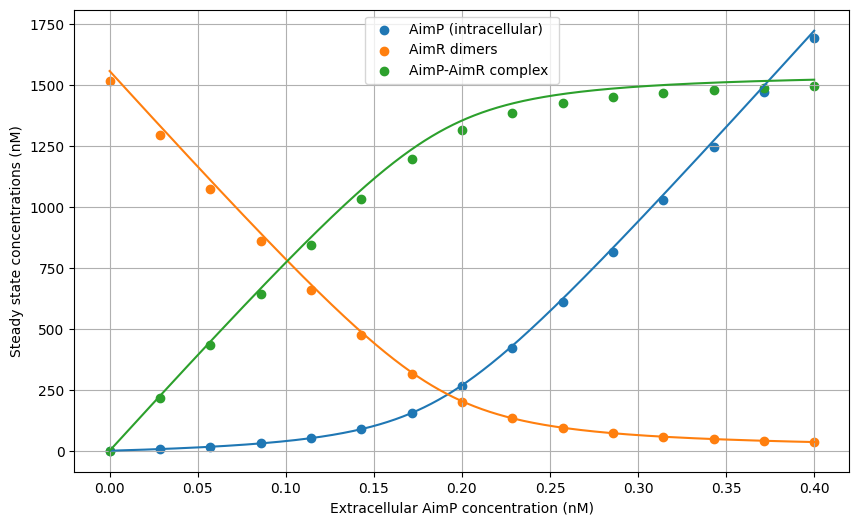

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(Pext, NumericalSteady_states[:, 0], label='AimP (intracellular) ')
plt.scatter(Pext, NumericalSteady_states[:, 1], label='AimR dimers')
plt.scatter(Pext, NumericalSteady_states[:, 2], label='AimP-AimR complex ')
plt.plot(Panalytical, Analyticalsteady_states[:, 0])
plt.plot(Panalytical, Analyticalsteady_states[:, 1])
plt.plot(Panalytical, Analyticalsteady_states[:, 2])
plt.xlabel('Extracellular AimP concentration (nM)')
plt.ylabel('Steady state concentrations (nM)')
plt.legend()
plt.grid()
plt.show()


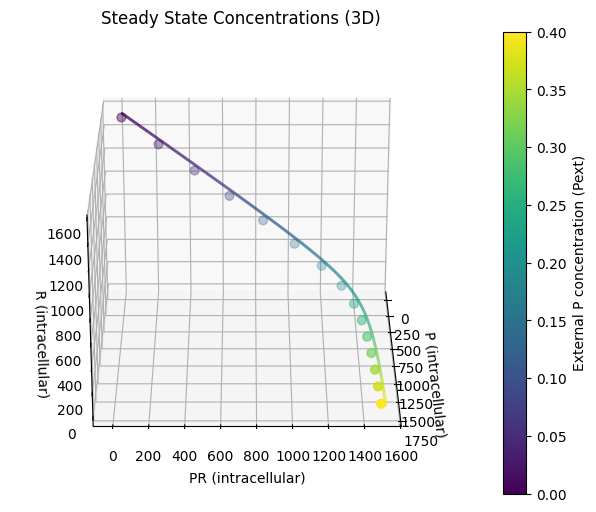

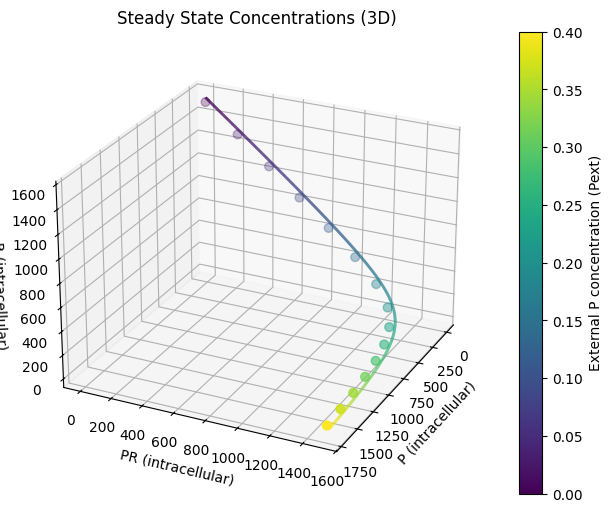

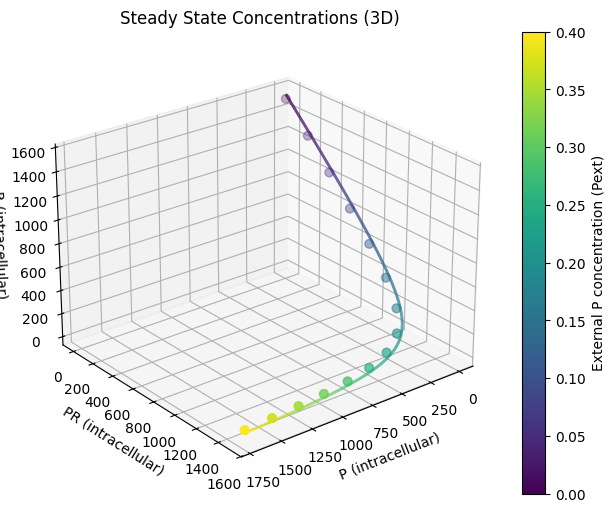

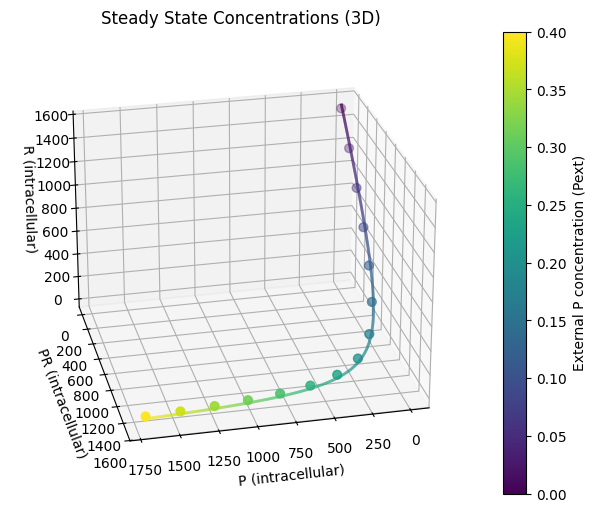

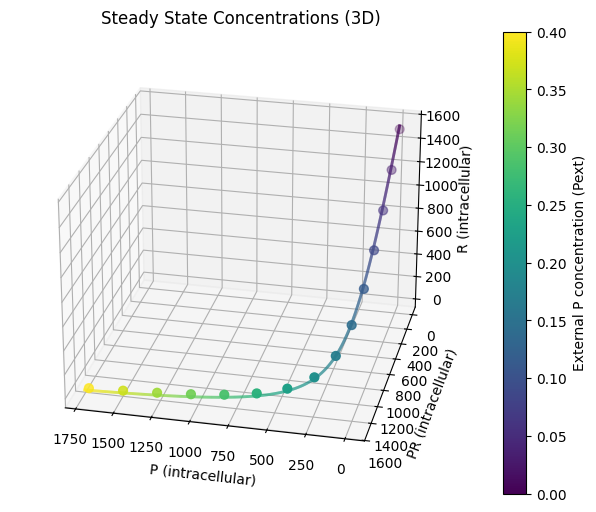

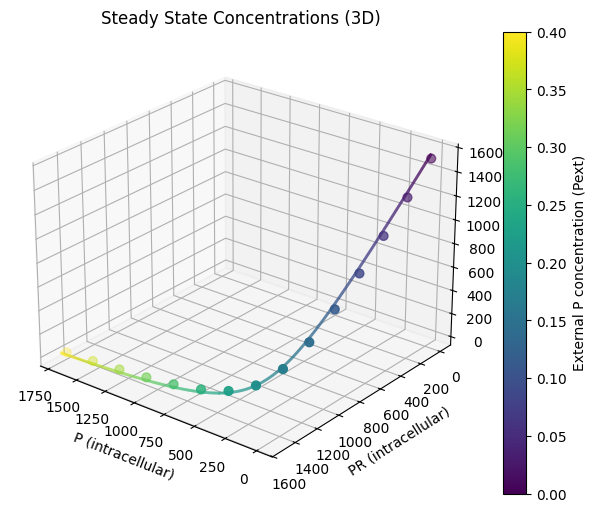

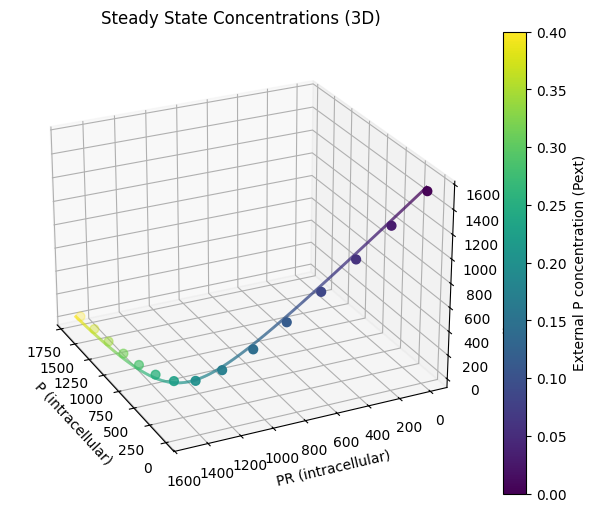

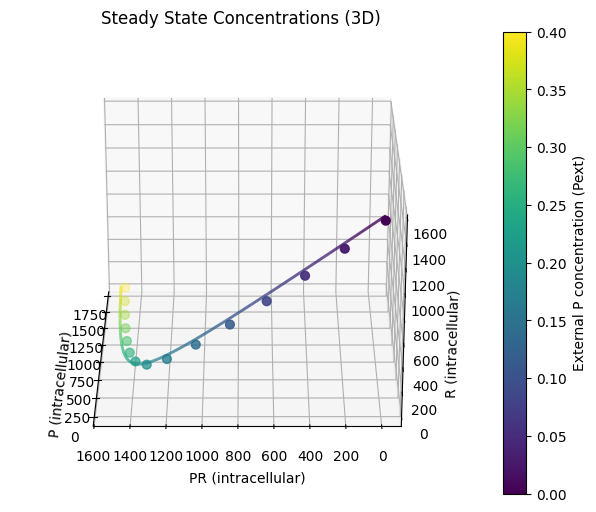

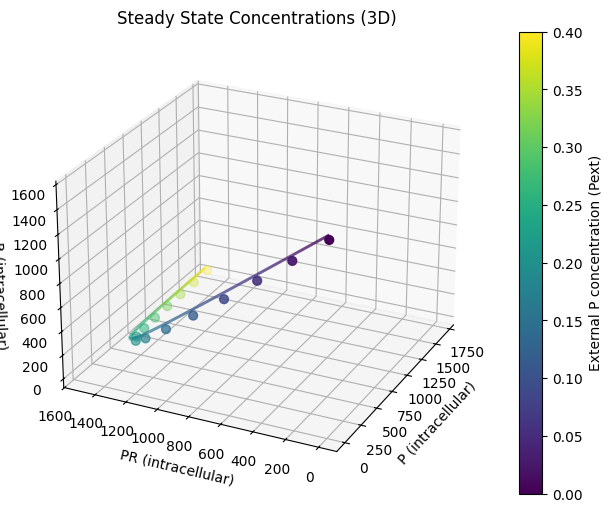

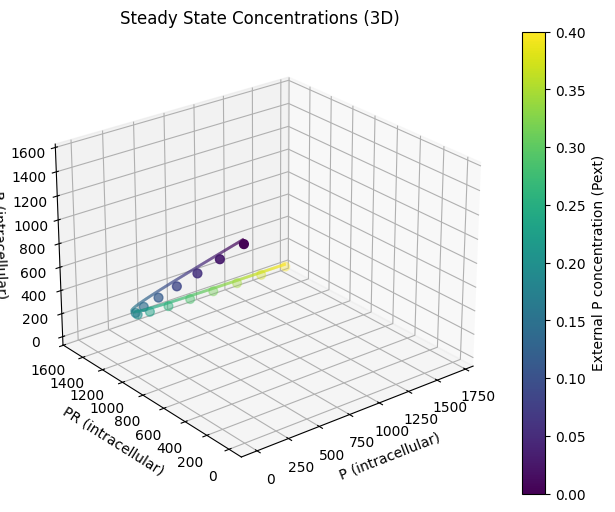

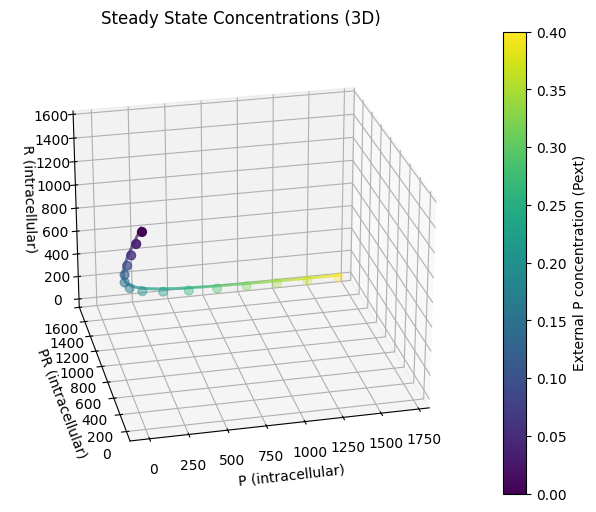

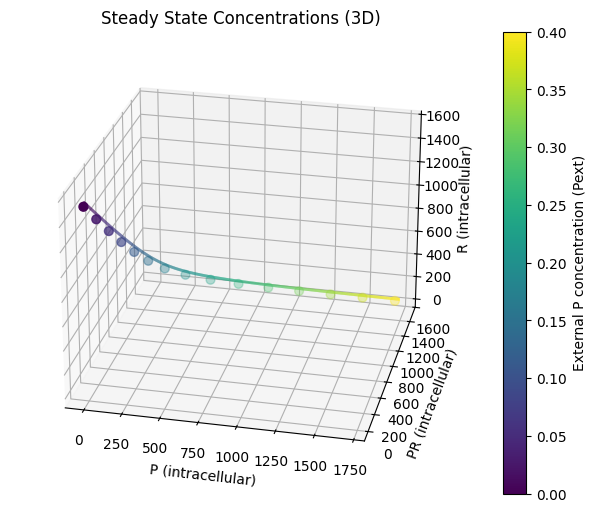

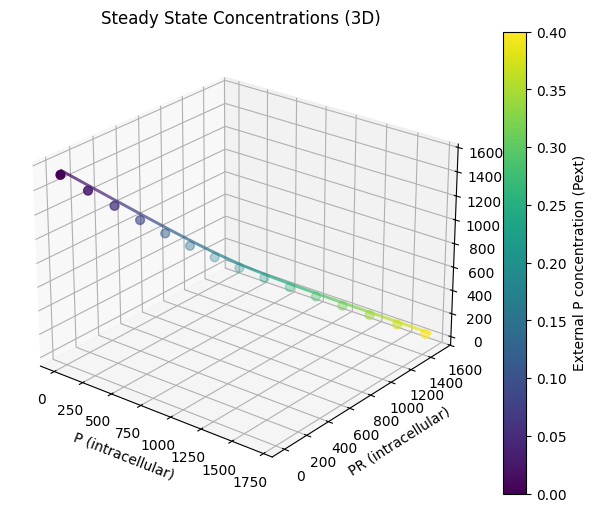

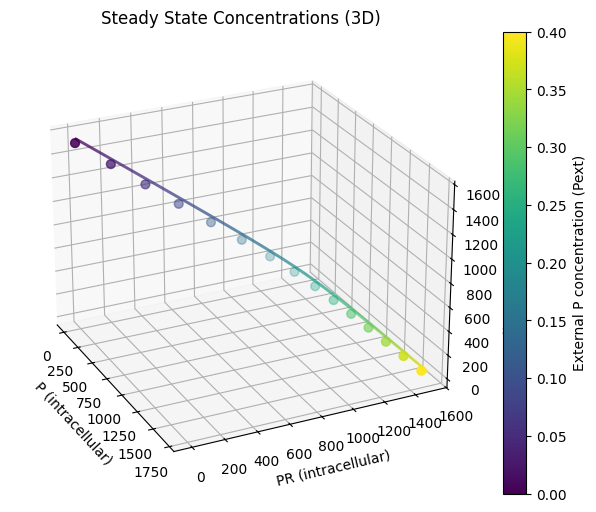

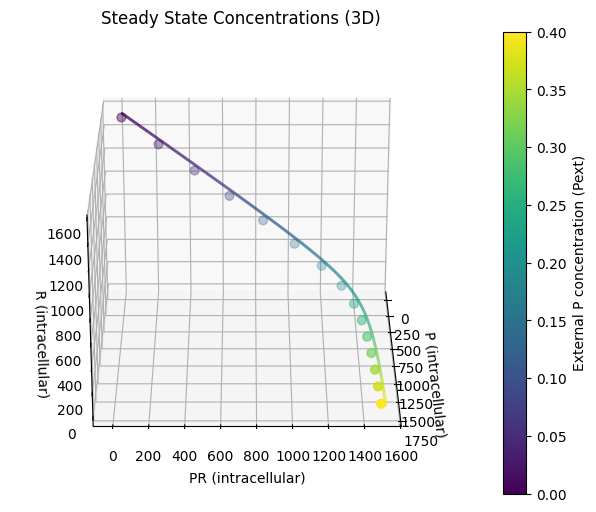

In [ ]:
from mpl_toolkits.mplot3d.art3d import Line3DCollection
import matplotlib as mpl

def plot_steady_states_3d(azim):
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection='3d')
    ax.scatter(NumericalSteady_states[:, 0], NumericalSteady_states[:, 2], NumericalSteady_states[:, 1], c=Pext, cmap='viridis', s=40)

    # Prepare segments for the analytical line
    points = Analyticalsteady_states[:, [0,2,1]]  # shape (N, 3)
    segments = np.array([points[:-1], points[1:]]).transpose(1,0,2)
    # Map Panalytical to colors
    norm = mpl.colors.Normalize(vmin=Panalytical.min(), vmax=Panalytical.max())
    lc = Line3DCollection(segments, cmap='viridis', norm=norm)
    lc.set_array(Panalytical[:-1])
    lc.set_linewidth(2)
    ax.add_collection(lc)

    ax.set_xlabel('P (intracellular)')
    ax.set_ylabel('PR (intracellular)')
    ax.set_zlabel('R (intracellular)')
    ax.set_title('Steady State Concentrations (3D)')
    plt.colorbar(lc, label='External P concentration (Pext)')
    ax.view_init(elev=25, azim=azim)
    plt.show()

for angle in np.linspace(0, 360, 15):
    plot_steady_states_3d(angle)